# 05 - Bottleneck and performance analysis

Where do patients wait? A **wait** is the time between two consecutive clinical steps (repeated lab tests are left out, as in the variant analysis).

Long gaps that are not waiting in the ER are kept apart: time on the ward or in intensive care, and the weeks before a patient returns.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent
sys.path.append(str(ROOT / 'src'))

from plot_style import apply_style, save_fig, BLUE, INK, INK_SECONDARY
from prepare_log import load_events, load_cases
from bottlenecks import (clinical_steps, transition_stats, er_waits, time_from_registration,
                         target_summary, format_hours, TARGET_HOURS)
from load_data import CASE_ID

apply_style()
events = load_events()
steps = clinical_steps(events)
table = transition_stats(steps)
hours = time_from_registration(events)
len(steps)

6701

## 1. Process map with waiting times
The same map as before, now with the **median time** on each arrow (s = seconds, m = minutes, h = hours, D = days, MO = months). Colour shows how slow the step is, red being the slowest.

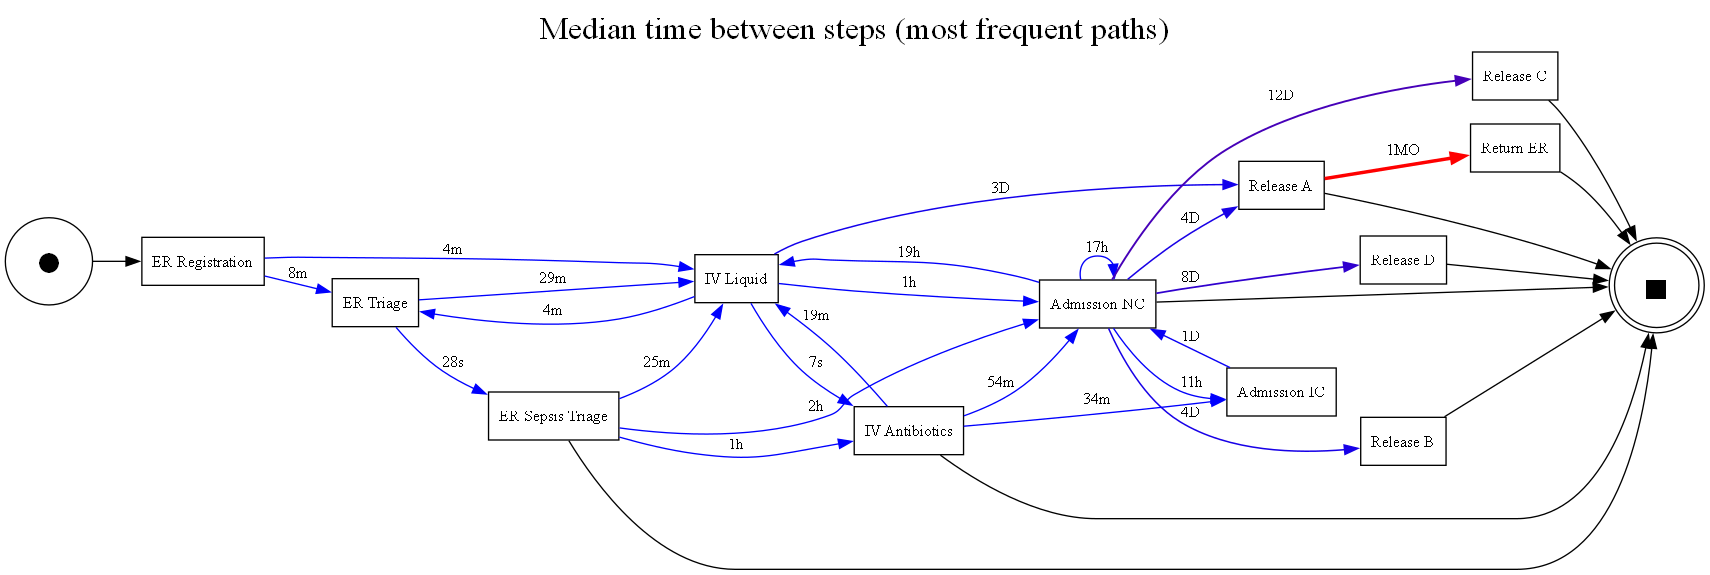

In [2]:
display(Image(ROOT / 'reports' / 'figures' / 'process_performance_dfg.png', width=1000))

## 2. Waits between ER steps
Each row is one pair of consecutive steps with at least 30 patients. The bar is the **median** wait, and the label also shows the 90th percentile (9 in 10 patients wait less than this).

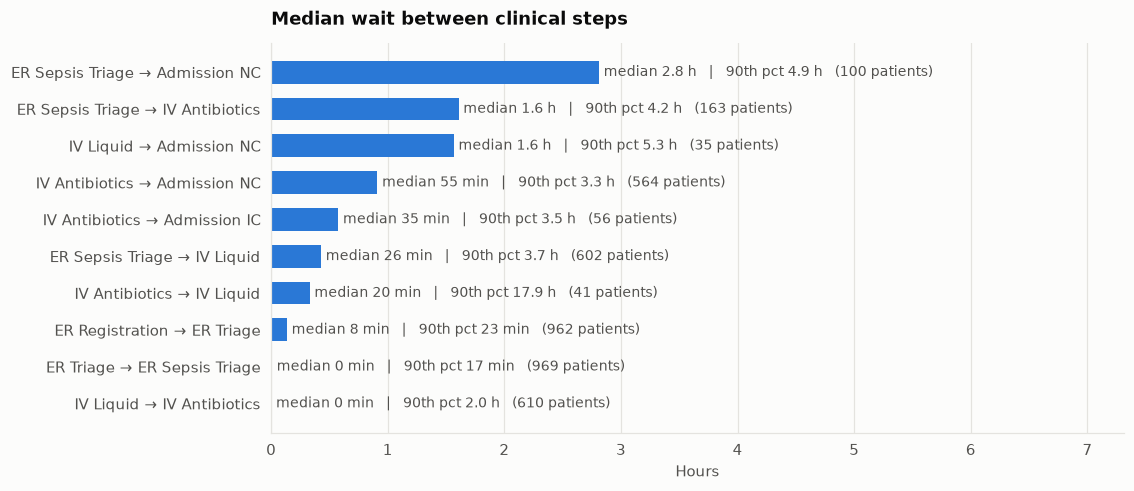

,from_step,to_step,cases,mean_hours,median_hours,p90_hours
9,IV Liquid,IV Antibiotics,610,0.48,0.00,2.00
8,ER Triage,ER Sepsis Triage,969,0.14,0.01,0.28
7,ER Registration,ER Triage,962,0.18,0.14,0.39
6,IV Antibiotics,IV Liquid,41,3.05,0.33,17.92
5,ER Sepsis Triage,IV Liquid,602,1.30,0.43,3.66
4,IV Antibiotics,Admission IC,56,1.26,0.58,3.54
3,IV Antibiotics,Admission NC,564,1.51,0.91,3.34
2,IV Liquid,Admission NC,35,13.81,1.57,5.34
1,ER Sepsis Triage,IV Antibiotics,163,1.77,1.61,4.24
0,ER Sepsis Triage,Admission NC,100,3.01,2.81,4.87


In [3]:
waits = er_waits(table).sort_values('median_hours')
labels = [f'{a} → {b}' for a, b in zip(waits['from_step'], waits['to_step'])]

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.barh(labels, waits['median_hours'], color=BLUE, height=0.62)
ax.grid(axis='y', visible=False)
for i, row in enumerate(waits.itertuples()):
    ax.text(row.median_hours + 0.04, i,
            f'median {format_hours(row.median_hours)}   |   90th pct {format_hours(row.p90_hours)}   ({row.cases} patients)',
            va='center', color=INK_SECONDARY, fontsize=9)
ax.set_xlim(0, waits['median_hours'].max() * 2.6)
ax.set_title('Median wait between clinical steps')
ax.set_xlabel('Hours')
save_fig(fig, 'bottleneck_er_waits')
plt.show()
waits[['from_step', 'to_step', 'cases', 'mean_hours', 'median_hours', 'p90_hours']].round(2)

## 3. Time from registration to each step
How long a patient has been in the ER when each step first happens.

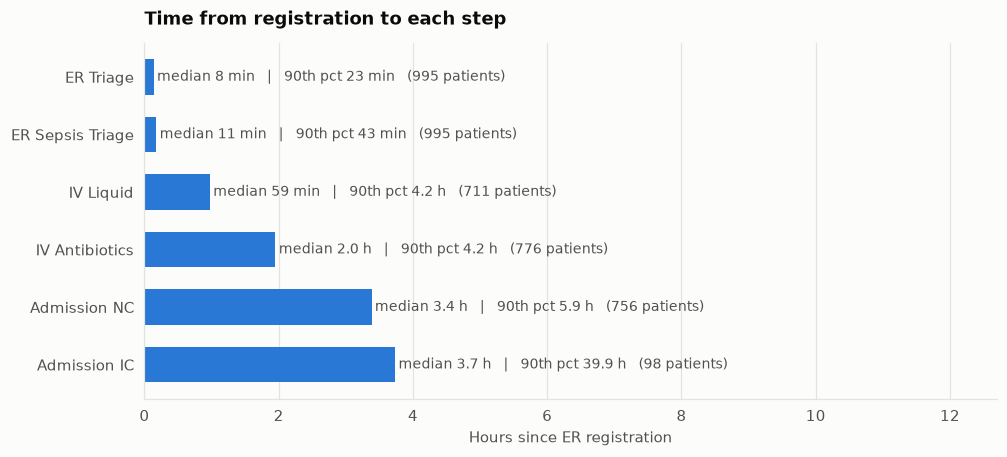

,cases,median_hours,p90_hours,within_1h_pct,within_3h_pct
ER Triage,995.0,0.14,0.38,99.70,100.00
ER Sepsis Triage,995.0,0.18,0.71,93.57,98.99
IV Liquid,711.0,0.98,4.22,50.63,77.50
IV Antibiotics,776.0,1.95,4.22,33.38,71.91
Admission NC,756.0,3.38,5.86,0.13,37.96
Admission IC,98.0,3.74,39.95,2.04,39.80


In [4]:
order = ['ER Triage', 'ER Sepsis Triage', 'IV Liquid', 'IV Antibiotics', 'Admission NC', 'Admission IC']
stats = pd.DataFrame({name: target_summary(hours[name]) for name in order}).T

fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(order))[::-1]
ax.barh(y, stats['median_hours'], color=BLUE, height=0.62)
ax.set_yticks(y)
ax.set_yticklabels(order)
ax.grid(axis='y', visible=False)
for yi, row in zip(y, stats.itertuples()):
    ax.text(row.median_hours + 0.05, yi,
            f'median {format_hours(row.median_hours)}   |   90th pct {format_hours(row.p90_hours)}   ({int(row.cases)} patients)',
            va='center', color=INK_SECONDARY, fontsize=9)
ax.set_xlim(0, stats['median_hours'].max() * 3.4)
ax.set_title('Time from registration to each step')
ax.set_xlabel('Hours since ER registration')
save_fig(fig, 'bottleneck_time_from_registration')
plt.show()
stats.round(2)

## 4. Time to antibiotics
Antibiotics within **1 hour** is the commonly quoted target for sepsis (Surviving Sepsis Campaign hour-1 bundle). Here the clock starts at **ER registration**, not at the moment sepsis was recognised, so the times are somewhat longer than the clinical measure. The 3-hour line is shown as a looser reference.

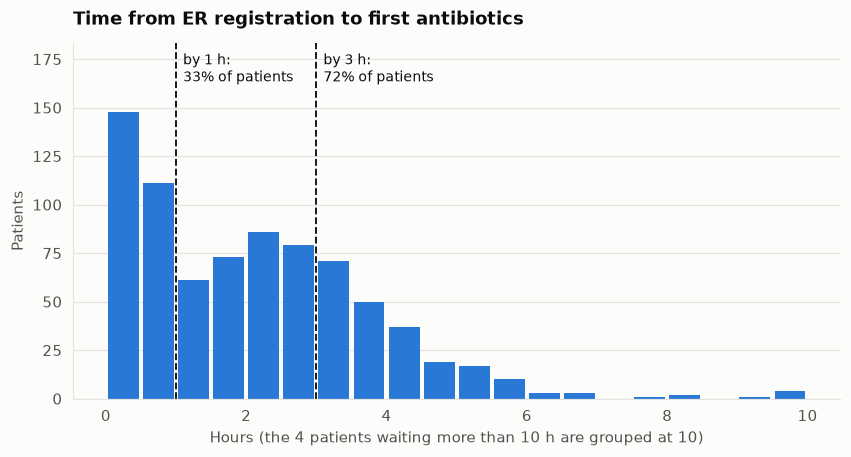

,value
cases,776.0
median_hours,2.0
p90_hours,4.2
within_1h_pct,33.4
within_3h_pct,71.9


In [5]:
abx = hours['IV Antibiotics'].dropna()
summary = target_summary(abx)
CAP = 10
n_over = int((abx > CAP).sum())

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.hist(abx.clip(upper=CAP), bins=np.arange(0, CAP + 0.5, 0.5), color=BLUE, rwidth=0.88)
ymax = ax.get_ylim()[1]
ax.set_ylim(0, ymax * 1.18)
for t, share in zip(TARGET_HOURS, (summary['within_1h_pct'], summary['within_3h_pct'])):
    ax.axvline(t, color=INK, linewidth=1.2, linestyle='--')
    ax.text(t + 0.1, ymax * 1.15, f'by {t} h:\n{share:.0f}% of patients', color=INK, fontsize=9, va='top')
ax.grid(axis='x', visible=False)
ax.set_title('Time from ER registration to first antibiotics')
ax.set_xlabel(f'Hours (the {n_over} patients waiting more than {CAP} h are grouped at {CAP})')
ax.set_ylabel('Patients')
save_fig(fig, 'bottleneck_time_to_antibiotics')
plt.show()
pd.Series(summary, name='value').round(1).to_frame()

In [6]:
cases = load_cases().set_index(CASE_ID)
print(f"Patients with antibiotics recorded: {len(abx)} of {len(cases)} ({len(abx) / len(cases) * 100:.0f}%)")

Patients with antibiotics recorded: 776 of 995 (78%)


## 5. Does arrival time matter?
Median time to antibiotics by the time of day the patient registered, and by weekday.

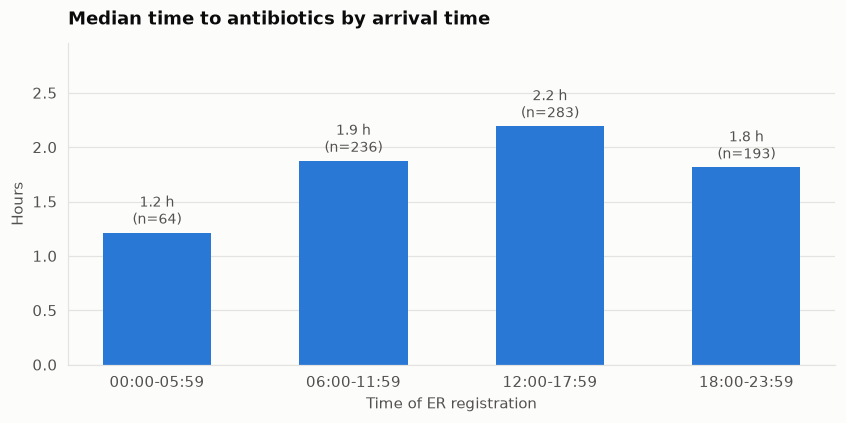

In [7]:
registration = events[events['concept:name'] == 'ER Registration'].groupby(CASE_ID)['time:timestamp'].first().reindex(abx.index)
block = pd.cut(registration.dt.hour, [-1, 5, 11, 17, 23], labels=['00:00-05:59', '06:00-11:59', '12:00-17:59', '18:00-23:59'])
by_block = abx.groupby(block).agg(patients='size', median='median')

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(by_block.index.astype(str), by_block['median'], color=BLUE, width=0.55)
ax.grid(axis='x', visible=False)
for i, row in enumerate(by_block.itertuples()):
    ax.text(i, row.median + 0.04, f'{format_hours(row.median)}\n(n={row.patients})', ha='center', va='bottom', color=INK_SECONDARY, fontsize=9)
ax.set_ylim(0, by_block['median'].max() * 1.35)
ax.set_title('Median time to antibiotics by arrival time')
ax.set_ylabel('Hours')
ax.set_xlabel('Time of ER registration')
save_fig(fig, 'bottleneck_arrival_time')
plt.show()

In [8]:
by_day = abx.groupby(registration.dt.dayofweek).agg(patients='size', median_hours='median')
by_day.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
by_day.round(2).T

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
patients,128.00,96.00,120.00,112.00,96.0,108.00,116.00
median_hours,2.25,1.77,1.71,1.77,2.1,1.77,2.19


## 6. Where does the time go?
Share of all the time between recorded steps while patients are in hospital. The weeks before a patient returns are excluded.

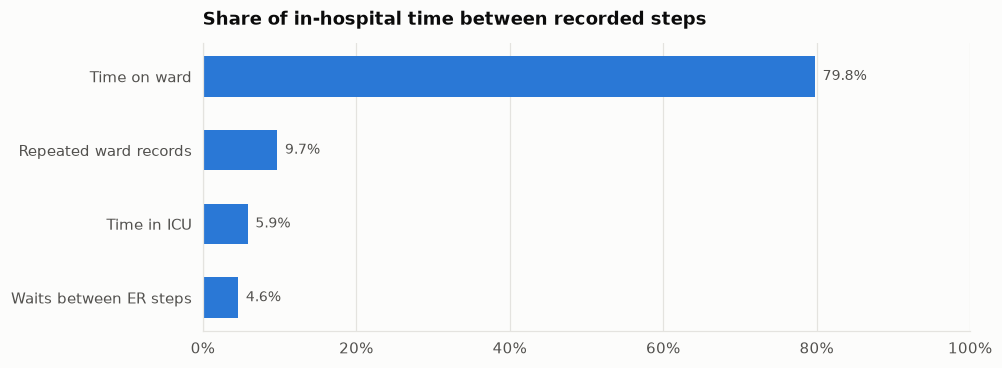

,share %
kind,
Waits between ER steps,4.6
Time in ICU,5.9
Repeated ward records,9.7
Time on ward,79.8


In [9]:
share = (table[table['kind'] != 'return to ER'].groupby('kind')['share_of_hospital_time_pct'].sum()
         .rename({'time on ward': 'Time on ward', 'repeated ward record': 'Repeated ward records',
                  'time in ICU': 'Time in ICU', 'wait between steps': 'Waits between ER steps'})
         .sort_values())

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(share.index, share.values, color=BLUE, height=0.55)
ax.grid(axis='y', visible=False)
for i, v in enumerate(share.values):
    ax.text(v + 1, i, f'{v:.1f}%', va='center', color=INK_SECONDARY, fontsize=9)
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
ax.set_title('Share of in-hospital time between recorded steps')
save_fig(fig, 'bottleneck_time_share')
plt.show()
share.round(1).to_frame('share %')

In [10]:
# Stays and returns, in days
def days(frame, from_step, to_prefix):
    rows = frame[(frame['from_step'] == from_step) & frame['to_step'].str.startswith(to_prefix)]
    return rows[['to_step', 'cases', 'median_hours', 'p90_hours']].assign(
        median_days=lambda d: d['median_hours'] / 24, p90_days=lambda d: d['p90_hours'] / 24).round(1)

print('Ward to discharge'); display(days(table, 'Admission NC', 'Release'))
print('ICU to ward'); display(days(table, 'Admission IC', 'Admission NC'))
print('Release A to return'); display(days(table, 'Release A', 'Return'))
repeat = table[table['kind'] == 'repeated ward record']
print('Repeated ward record: cases', int(repeat['cases'].iloc[0]), 'median hours between', round(float(repeat['median_hours'].iloc[0]), 1))

Ward to discharge


,to_step,cases,median_hours,p90_hours,median_days,p90_days
2,Release A,618,108.9,265.7,4.5,11.1
13,Release B,40,101.4,261.6,4.2,10.9
19,Release D,23,212.2,469.8,8.8,19.6
20,Release C,20,307.2,624.4,12.8,26.0


ICU to ward


,to_step,cases,median_hours,p90_hours,median_days,p90_days
10,Admission NC,85,40.7,145.3,1.7,6.1


Release A to return


,to_step,cases,median_hours,p90_hours,median_days,p90_days
7,Return ER,262,1116.5,5129.6,46.5,213.7


Repeated ward record: cases 320 median hours between 17.6


## Findings

**Four main insights**
1. **The ER front door is fast, but treatment starts later.** Only 33% of patients receive antibiotics within 1 hour of registration (72% within 3 hours).
2. **Patients who skip IV fluid wait longer** for the next step.
3. **Arrival time has only a modest effect.** Night arrivals are not slower, and the busy afternoon is the slowest.
4. **The ward, not the ER, is where most time goes** (about 80% of in-hospital time), and returns happen after a median of 46 days.

**Details**
- **Front door:** registration to triage takes a median of 8 minutes (90th percentile 23 minutes), and triage to sepsis triage is almost immediate. 94% of patients have had sepsis triage within an hour of registering.
- **Time to treatment:** median 59 minutes from registration to IV fluid (711 patients) and 2.0 hours to antibiotics (776 patients). The 90th percentile for antibiotics is 4.2 hours. 219 patients (22%) have no antibiotics recorded.
- **Against the 1-hour target:** the commonly quoted sepsis target is antibiotics within 1 hour. The clock here starts at registration, not when sepsis was recognised, so the true share meeting the target is probably higher. This is still the clearest improvement area in the data.
- **Skipping IV fluid:** the 163 patients who got antibiotics without IV fluid waited a median of 1.6 hours after sepsis triage, and the 100 patients who went from sepsis triage straight to the ward waited a median of 2.8 hours, the longest typical wait between steps. Patients who got fluid first waited a median of 26 minutes for it, and then antibiotics followed at once. Whether this is cause or effect (for example, milder cases being treated differently) cannot be told from the data.
- **Care that is recorded together:** IV fluid to antibiotics has a median of 0 minutes, so the two are mostly recorded at the same time. They may be entered together rather than given together.
- **To the ward:** antibiotics to ward admission takes a median of 55 minutes. From registration, the median is 3.4 hours, and only 38% of patients are on the ward within 3 hours.
- **Arrival time:** median time to antibiotics is 1.2 hours for arrivals from 00:00 to 05:59 (64 patients), 1.9 hours from 06:00 to 11:59, 2.2 hours from 12:00 to 17:59 (283 patients) and 1.8 hours from 18:00 to 23:59. Weekdays range from 1.7 to 2.3 hours. The afternoon is the busiest period, so workload may play a role, but the differences are small and not proven.
- **Where the time goes:** time on the ward is 79.8% of in-hospital time between recorded steps, repeated ward records 9.7%, ICU 5.9%, and waits between ER steps only 4.6%. The ward stay to Release A has a median of 4.5 days (90th percentile 11 days). Release C patients stay a median 12.8 days and Release D 8.8 days. After ICU, patients return to the ward after a median of 1.7 days (85 patients).
- **Repeated ward records:** `Admission NC` is recorded again directly after itself 320 times, a median of 17.6 hours apart. This could be daily records or transfers and should be checked with the mentor.
- **Returns:** the 262 patients who return to the ER after Release A do so after a median of 46.5 days (90th percentile 214 days). This is the time until the patient comes back, not a hospital wait.
- **Limits:** times come from recorded timestamps, which may be entered after the event. The results are medians over retrospective data and show where delays occur, not why.
- **Next steps:** a basic dashboard (commit 10) will show these results interactively, and conformance checking in the second half will test the pathways against an expected sepsis pathway.
